# Exercise 2: Logistic Regression — Direct Marketing Conversion

## Objective

Build a Logistic Regression classifier to predict whether a
bank customer will subscribe to a term deposit.

### Target
- y

### Numeric Features
- age
- balance
- duration
- campaign

### Categorical Features
- job
- poutcome

### Model
- Logistic Regression

### Key Techniques
- Class weighting
- RobustScaler
- OneHotEncoder
- Threshold calibration

### Evaluation Metrics
- ROC-AUC
- Precision
- Recall
- F1-score

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-Learn:", sklearn.__version__)

Python: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.0.6
NumPy: 2.5.3
Scikit-Learn: 1.9.1


## 1. Data Ingestion

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank_marketing.csv"

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Dataset path: c:\Users\bhite\ml-engineering-lab-series-01\data\raw\bank_marketing.csv
Dataset exists: True


In [3]:
df = pd.read_csv(DATA_PATH, sep=";")

In [4]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (41188, 21)

Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank_marketing.csv"

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset shape:", df.shape)
display(df.head())

Dataset path: c:\Users\bhite\ml-engineering-lab-series-01\data\raw\bank_marketing.csv
Dataset exists: True
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data Quality Checks

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [7]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 12


In [9]:
display(df.describe(include="all"))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.00000,41188,41188,41188,41188,41188,41188,41188,41188,41188,...,41188.000000,41188.000000,41188.000000,41188,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188
unique,NaN,12,4,8,3,3,3,2,10,5,...,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2
top,NaN,admin.,married,university.degree,no,yes,no,cellular,may,thu,...,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no
freq,NaN,10422,24928,12168,32588,21576,33950,26144,13769,8623,...,NaN,NaN,NaN,35563,NaN,NaN,NaN,NaN,NaN,36548
mean,40.02406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.567593,962.475454,0.172963,NaN,0.081886,93.575664,-40.502600,3.621291,5167.035911,NaN
std,10.42125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.770014,186.910907,0.494901,NaN,1.570960,0.578840,4.628198,1.734447,72.251528,NaN
min,17.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,0.000000,0.000000,NaN,-3.400000,92.201000,-50.800000,0.634000,4963.600000,NaN
25%,32.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,999.000000,0.000000,NaN,-1.800000,93.075000,-42.700000,1.344000,5099.100000,NaN
50%,38.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.000000,999.000000,0.000000,NaN,1.100000,93.749000,-41.800000,4.857000,5191.000000,NaN
75%,47.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.000000,999.000000,0.000000,NaN,1.400000,93.994000,-36.400000,4.961000,5228.100000,NaN


In [10]:
required_columns = [
    "age",
    "job",
    "balance",
    "duration",
    "campaign",
    "poutcome",
    "y"
]

missing_columns = set(required_columns) - set(df.columns)

print("Missing required columns:")
print(missing_columns)

Missing required columns:
{'balance'}


In [11]:
print("Target distribution:")
print(df["y"].value_counts())

Target distribution:
y
no     36548
yes     4640
Name: count, dtype: int64


In [12]:
print("\nTarget percentage:")
print(df["y"].value_counts(normalize=True) * 100)


Target percentage:
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


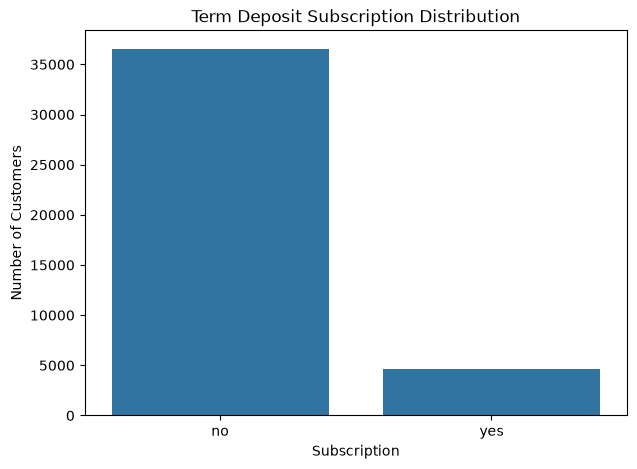

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

In [14]:
df["y"] = df["y"].map({
    "no": 0,
    "yes": 1
})

In [15]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank_marketing.csv"

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset path: c:\Users\bhite\ml-engineering-lab-series-01\data\raw\bank_marketing.csv
Dataset exists: True
Dataset shape: (41188, 21)

Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [16]:
features = [
    "age",
    "job",
    "duration",
    "campaign",
    "poutcome"
]

X = df[features]
y = df["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (41188, 5)
y shape: (41188,)


In [17]:
numeric_features = [
    "age",
    "duration",
    "campaign"
]

categorical_features = [
    "job",
    "poutcome"
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['age', 'duration', 'campaign']
Categorical features: ['job', 'poutcome']


In [18]:
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['age', 'duration', 'campaign']
Categorical features: ['job', 'poutcome']


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 30891
Testing samples: 10297

Training target distribution:
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

Testing target distribution:
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Features available in our dataset
features = ["age", "job", "duration", "campaign", "poutcome"]

X = df[features]
y = df["y"].map({"no": 0, "yes": 1})

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

numeric_features = ["age", "duration", "campaign"]
categorical_features = ["job", "poutcome"]

preprocessor = ColumnTransformer([
    ("num", RobustScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

model.fit(X_train, y_train)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain distribution:")
print(y_train.value_counts(normalize=True))
print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

Train shape: (30891, 5)
Test shape: (10297, 5)

Train distribution:
y
0    0.887346
1    0.112654
Name: proportion, dtype: float64

Test distribution:
y
0    0.887346
1    0.112654
Name: proportion, dtype: float64


In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve
)

# Probability predictions
y_prob = model.predict_proba(X_test)[:, 1]

# Default threshold = 0.50
y_pred_50 = (y_prob >= 0.50).astype(int)

print("=== Threshold 0.50 ===")
print(classification_report(y_test, y_pred_50))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_50))

# Lab-required threshold
threshold = 0.35
y_pred_35 = (y_prob >= threshold).astype(int)

print("\n=== Threshold 0.35 ===")
print(classification_report(y_test, y_pred_35))
print("Recall:", recall_score(y_test, y_pred_35))
print("Precision:", precision_score(y_test, y_pred_35))
print("F1:", f1_score(y_test, y_pred_35))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_35))

=== Threshold 0.50 ===
              precision    recall  f1-score   support

           0       0.96      0.85      0.90      9137
           1       0.38      0.75      0.51      1160

    accuracy                           0.84     10297
   macro avg       0.67      0.80      0.70     10297
weighted avg       0.90      0.84      0.86     10297

ROC-AUC: 0.8789378068708886
Confusion Matrix:
 [[7742 1395]
 [ 295  865]]

=== Threshold 0.35 ===
              precision    recall  f1-score   support

           0       0.98      0.73      0.84      9137
           1       0.29      0.86      0.43      1160

    accuracy                           0.75     10297
   macro avg       0.63      0.79      0.63     10297
weighted avg       0.90      0.75      0.79     10297

Recall: 0.8551724137931035
Precision: 0.2879535558780842
F1: 0.4308360477741585
Confusion Matrix:
 [[6684 2453]
 [ 168  992]]


In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, recall_score

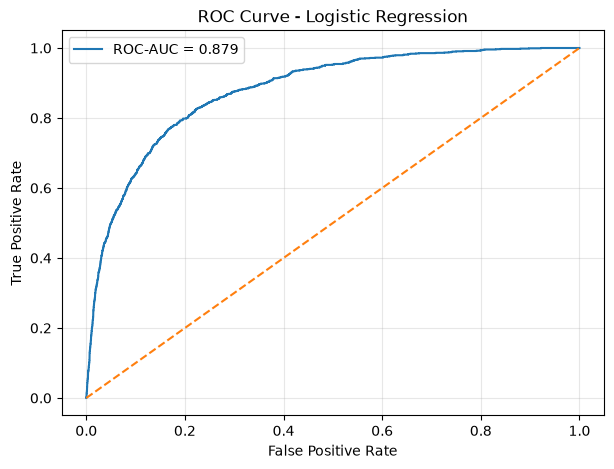

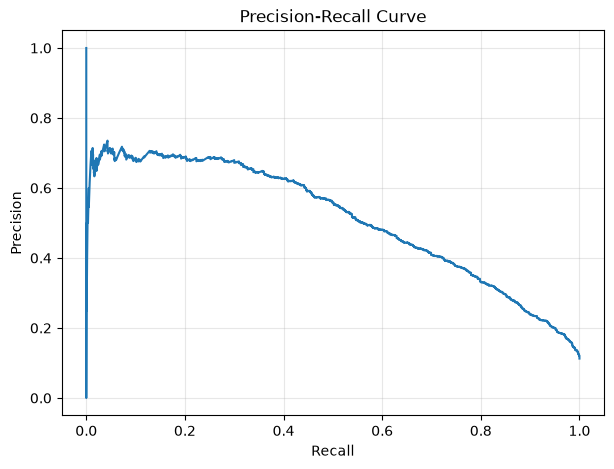

========== ACCEPTANCE CHECK ==========
ROC-AUC: 0.8789  | Required >= 0.78
Recall @ 0.35: 0.8552 | Required >= 0.70
PASS

Saved: c:\Users\bhite\ml-engineering-lab-series-01\outputs\exercise2_predictions.csv


In [23]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(7,5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.show()

# Acceptance criteria
roc_auc = roc_auc_score(y_test, y_prob)
recall_35 = recall_score(y_test, y_pred_35)

print("========== ACCEPTANCE CHECK ==========")
print(f"ROC-AUC: {roc_auc:.4f}  | Required >= 0.78")
print(f"Recall @ 0.35: {recall_35:.4f} | Required >= 0.70")

if roc_auc >= 0.78 and recall_35 >= 0.70:
    print("PASS")
else:
    print("Needs improvement / tuning")

# Save predictions
predictions = X_test.copy()
predictions["actual_y"] = y_test.values
predictions["probability"] = y_prob
predictions["prediction_035"] = y_pred_35

output_path = PROJECT_ROOT / "outputs" / "exercise2_predictions.csv"
predictions.to_csv(output_path, index=False)

print("\nSaved:", output_path)